# NetZeroAI - Index Construction, Clustering & Validation Walkthrough

Walks through the same steps as `src/pipeline/train_pipeline.py` one component at a time, then the robustness checks from `src/components/index_validation.py`. The pipeline itself is the source of truth; this notebook is for inspection.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import constants as C

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

from src.components.data_ingestion import DataIngestion
from src.components.data_transformation import DataTransformation
from src.components.index_validation import IndexValidation
from src.components.model_trainer import ModelTrainer

## 1. Composite index

Percentile-normalize the five indicators, average them into four dimensions, and combine with equal 25% weights. Tiers are quartiles of the composite.

In [2]:
train_path, test_path = DataIngestion().initiate_data_ingestion()
train_df, test_df = DataTransformation().initiate_data_transformation(train_path, test_path)
dim_cols = [f"{d}_score" for d in C.DIMENSIONS]
train_df.sort_values("netzero_index_score", ascending=False)[["country", "netzero_index_score", "tier"] + dim_cols].head(15).round(1)

,country,netzero_index_score,tier,emissions_intensity_score,decarbonization_trajectory_score,energy_transition_score,economic_capacity_score
103,Macao,76.0,Leader,77.1,79.4,61.3,86.1
168,Switzerland,75.8,Leader,48.7,84.5,72.2,97.9
48,Denmark,75.8,Leader,30.4,93.3,85.1,94.3
167,Sweden,74.7,Leader,45.4,83.5,77.8,92.3
129,Norway,74.2,Leader,16.5,86.1,94.8,99.5
41,Costa Rica,73.9,Leader,68.3,62.4,100.0,64.9
1,Albania,73.5,Leader,70.6,64.9,100.0,58.2
102,Luxembourg,72.7,Leader,10.3,97.9,86.6,95.9
79,Iceland,71.9,Leader,9.8,87.6,100.0,90.2
184,United Kingdom,70.6,Leader,37.9,94.8,62.4,87.1


In [3]:
train_df.sort_values("netzero_index_score")[["country", "netzero_index_score", "tier"] + dim_cols].head(10).round(1)

,country,netzero_index_score,tier,emissions_intensity_score,decarbonization_trajectory_score,energy_transition_score,economic_capacity_score
25,Brunei,11.3,Lagging,1.0,0.0,5.2,39.2
179,Turkmenistan,18.2,Lagging,5.4,1.0,6.2,60.3
11,Bahamas,20.2,Lagging,22.4,2.6,9.8,45.9
74,Guyana,21.1,Lagging,17.8,1.5,13.4,51.5
114,Mongolia,23.5,Lagging,4.6,4.1,25.3,59.8
83,Iraq,24.2,Lagging,26.8,7.2,12.9,50.0
107,Maldives,24.8,Lagging,45.6,3.1,21.1,29.4
12,Bahrain,25.2,Lagging,1.3,5.7,7.2,86.6
82,Iran,25.8,Lagging,14.2,4.6,17.0,67.5
4,Antigua and Barbuda,25.9,Lagging,25.3,12.4,20.1,45.9


## 2. PCA + KMeans (independent cross-check)

In [4]:
train_df, test_df, k_table, silhouette, explained_var = ModelTrainer().initiate_model_training(train_df, test_df)
print(f"Silhouette at k={C.N_CLUSTERS_DEFAULT}: {silhouette:.3f}")
print("PCA explained variance:", np.round(explained_var, 3))
k_table.round(3)

Silhouette at k=4: 0.297
PCA explained variance: [0.536 0.218]


,k,inertia,silhouette
0,2,575.133,0.348
1,3,447.086,0.335
2,4,372.190,0.297
3,5,329.088,0.263
4,6,291.139,0.264
5,7,264.743,0.263


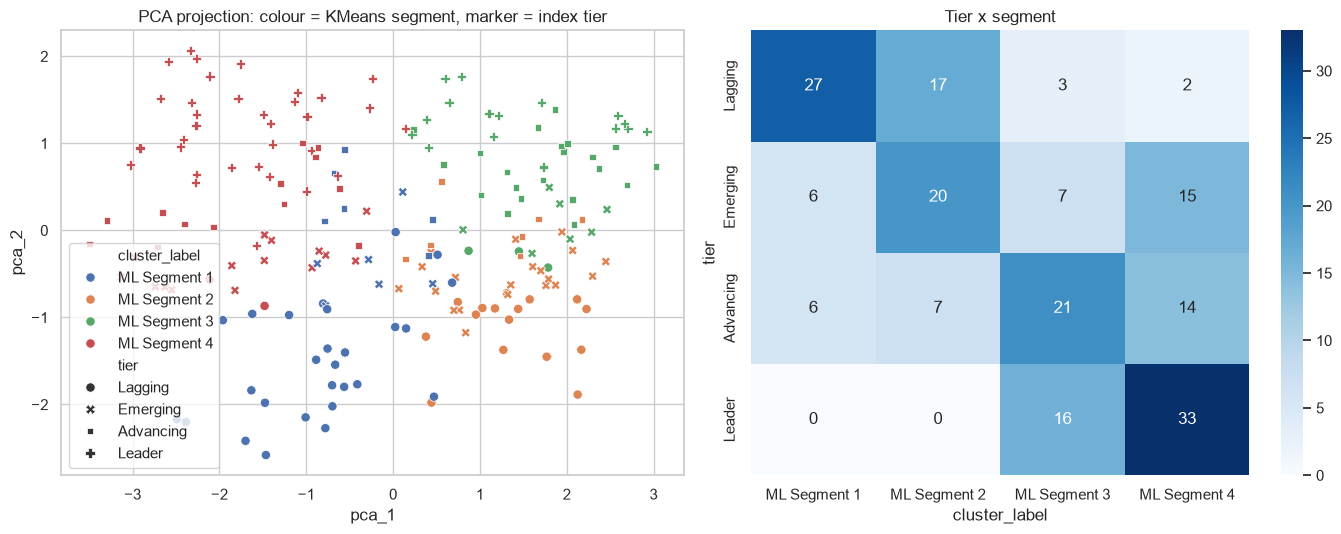

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=train_df, x="pca_1", y="pca_2", hue="cluster_label", style="tier",
                hue_order=sorted(train_df.cluster_label.unique()), ax=axes[0], s=45)
axes[0].set_title("PCA projection: colour = KMeans segment, marker = index tier")
crosstab = pd.crosstab(train_df["tier"], train_df["cluster_label"]).reindex(C.TIER_LABELS)
sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Tier x segment")
plt.tight_layout()
plt.show()

## 3. Robustness and validation

`IndexValidation` re-scores the index under alternative weightings and methods, runs a Monte Carlo over random weights, measures tier/segment agreement, and bootstraps KMeans stability.

In [6]:
train_df, report = IndexValidation().initiate_index_validation(train_df)
sens = report["sensitivity"]
pd.DataFrame(sens["weight_scenarios"] + sens["method_alternatives"]).drop(columns="weights").round(3)

,scenario,spearman_vs_baseline,mean_abs_rank_shift,max_abs_rank_shift,max_shift_country,tier_change_pct,top10_overlap
0,Drop Emissions Intensity,0.872,22.541,74,Oman,42.268,6
1,Drop Decarbonization Trajectory,0.807,28.356,74,United Arab Emirates,54.639,7
2,Drop Energy Transition,0.793,28.593,81,Democratic Republic of Congo,46.907,5
3,Drop Economic Capacity,0.813,28.294,72,Qatar,46.907,2
4,Double Emissions Intensity,0.870,23.454,69,Australia,43.299,5
5,Double Decarbonization Trajectory,0.944,13.938,62,Trinidad and Tobago,25.258,8
6,Double Energy Transition,0.947,13.959,48,Hong Kong,30.412,9
7,Double Economic Capacity,0.896,19.887,63,Taiwan,37.629,8
8,Geometric aggregation,0.871,20.722,102,Burundi,38.144,7
9,Min-max normalization,0.835,25.010,98,North Korea,46.392,8


{'n_draws': 1000, 'weight_spread': 0.5, 'mean_spearman': 0.954, 'min_spearman': 0.739, 'median_rank_band_width': 48.0, 'max_rank_band_width': 116, 'pct_countries_tier_stable_80': 47.423, 'pct_countries_tier_stable_95': 25.773}


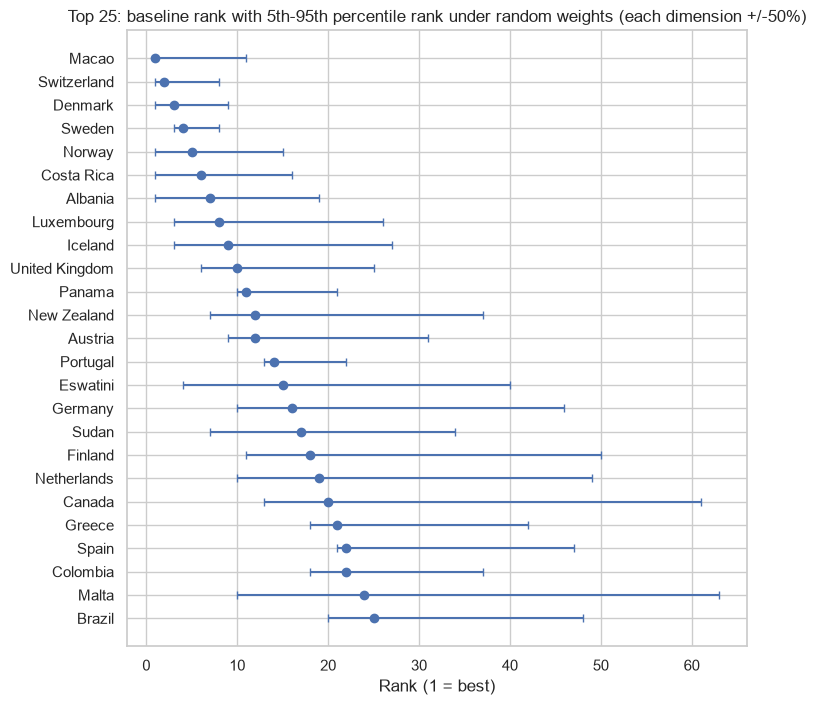

In [7]:
mc = sens["monte_carlo"]
print({k: round(v, 3) if isinstance(v, float) else v for k, v in mc.items()})
top = train_df.sort_values("rank").head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.errorbar(top["rank"], top["country"], xerr=[top["rank"] - top["weight_rank_p05"], top["weight_rank_p95"] - top["rank"]],
            fmt="o", capsize=3)
ax.set(xlabel="Rank (1 = best)", title="Top 25: baseline rank with 5th-95th percentile rank under random weights (each dimension +/-50%)")
plt.show()

The weight bands above ignore imputation. The imputation check below sets each imputed value to the lowest and highest observed value in its imputation peer group and records the resulting rank range.

In [8]:
imp = sens["imputation"]
print({k: v for k, v in imp.items() if k != "countries"})
pd.DataFrame([{"country": r["country"], "rank": r["baseline_rank"], "rank_range": r["rank_range"],
               "tier": r["baseline_tier"], "tier_range": r["tier_range"]} for r in imp["countries"]])

{'method': 'imputed value set to the min and max observed value of its imputation peer group', 'n_countries': 31, 'n_tier_can_change': 23, 'median_rank_range_width': 79.0}


,country,rank,rank_range,tier,tier_range
0,Macao,1,"[1, 65]",Leader,"[Advancing, Leader]"
1,Sudan,17,"[15, 30]",Leader,"[Leader, Leader]"
2,Fiji,50,"[11, 130]",Advancing,"[Emerging, Leader]"
3,Samoa,52,"[11, 132]",Advancing,"[Emerging, Leader]"
4,Kiribati,58,"[14, 132]",Advancing,"[Emerging, Leader]"
5,Suriname,63,"[31, 93]",Advancing,"[Advancing, Leader]"
6,Vanuatu,70,"[21, 149]",Advancing,"[Lagging, Leader]"
7,Solomon Islands,77,"[22, 151]",Advancing,"[Lagging, Leader]"
8,Bhutan,85,"[31, 114]",Advancing,"[Emerging, Leader]"
9,Papua New Guinea,104,"[47, 177]",Emerging,"[Lagging, Leader]"


In [9]:
agree = report["tier_cluster_agreement"]
print({k: round(v, 3) for k, v in agree.items() if isinstance(v, float)})
# Chance level for position-based agreement: random segments re-numbered by mean score, as model_trainer does.
print({k: round(v, 4) for k, v in agree["permutation_baseline"].items()})
pd.DataFrame(agree["cluster_profiles"]).set_index("cluster_label")

{'adjusted_rand_index': 0.179, 'normalized_mutual_info': 0.24, 'exact_agreement_pct': 52.062, 'within_one_step_pct': 86.598, 'spearman_tier_vs_cluster': 0.641}
{'n_permutations': 1000, 'exact_agreement_mean_pct': 27.732, 'exact_agreement_p95_pct': 32.4742, 'exact_agreement_p_value': 0.001, 'within_one_step_mean_pct': 66.2144, 'within_one_step_p_value': 0.001}


,emissions_intensity_score,decarbonization_trajectory_score,energy_transition_score,economic_capacity_score,netzero_index_score,n_countries,dominant_tier
cluster_label,,,,,,,
ML Segment 1,30.8,14.3,41.2,61.3,36.9,39,Lagging
ML Segment 2,74.7,42.2,29.1,28.5,43.6,44,Emerging
ML Segment 3,73.7,43.4,81.7,25.0,56.0,47,Advancing
ML Segment 4,26.5,81.2,48.1,77.7,58.4,64,Leader


In [10]:
pd.DataFrame(report["cluster_stability"]["by_k"]).round(3)

,k,mean_ari,p05_ari,min_ari
0,2,0.994,0.957,0.939
1,3,0.971,0.940,0.832
2,4,0.934,0.821,0.793
3,5,0.811,0.612,0.604
4,6,0.793,0.605,0.587
5,7,0.704,0.486,0.479


## 4. Anchor countries and scoring a new country

In [11]:
train_df[train_df.country.isin(C.ANCHOR_COUNTRIES)].sort_values("netzero_index_score", ascending=False)[
    ["country", "netzero_index_score", "rank", "weight_rank_p05", "weight_rank_p95", "tier", "weight_tier_stability", "cluster_label"]
].round(2)

,country,netzero_index_score,rank,weight_rank_p05,weight_rank_p95,tier,weight_tier_stability,cluster_label
167,Sweden,74.74,4,3,8,Leader,1.00,ML Segment 4
129,Norway,74.23,5,1,15,Leader,1.00,ML Segment 4
79,Iceland,71.91,9,3,27,Leader,0.99,ML Segment 4
67,Germany,67.78,16,10,46,Leader,0.96,ML Segment 4
63,France,63.72,27,20,62,Leader,0.87,ML Segment 4
60,Ethiopia,62.56,29,8,73,Leader,0.74,ML Segment 3
185,United States,60.70,40,21,100,Leader,0.58,ML Segment 4
126,Nigeria,53.87,81,52,101,Advancing,0.88,ML Segment 2
140,Qatar,51.93,89,37,153,Advancing,0.43,ML Segment 4
80,India,39.76,153,135,164,Lagging,0.81,ML Segment 2


In [12]:
from src.pipeline.predict_pipeline import CustomCountryData, PredictPipeline

india = train_df[train_df.country == "India"].iloc[0]
scenario = CustomCountryData(
    co2_per_capita=india.co2_per_capita,
    ghg_per_capita=india.ghg_per_capita,
    co2pc_trend_slope=india.co2pc_trend_slope,
    renewables_share_elec=50.0,          # what if India's grid were 50% renewable?
    gdp_per_capita=india.gdp_per_capita,
    country="India, 50% renewable grid",
).to_dataframe()
result = PredictPipeline().predict(scenario)
print(f"India actual: {india.netzero_index_score:.1f} ({india.tier})")
result[["country", "netzero_index_score", "tier", "cluster_label"]].round(1)

India actual: 39.8 (Lagging)


,country,netzero_index_score,tier,cluster_label
0,"India, 50% renewable grid",46.7,Emerging,ML Segment 3
